# Bài 5 (Trang 26): Gom cụm K-Means trên bộ dữ liệu MNIST
**Họ tên:** Trần Minh Tấn - **MSSV:** 6451071071

**Ý tưởng:** K-Means là thuật toán *học không giám sát*, tự chia ảnh thành 10 cụm mà **không dùng nhãn**. Sau đó ta mới đem so sánh các cụm với nhãn thật (0-9) để xem K-Means gom có đúng không.

## 1. Đọc dữ liệu MNIST từ Keras

In [1]:
  import numpy as np
  import pandas as pd
  import matplotlib.pyplot as plt
  import seaborn as sns
  from tensorflow.keras.datasets import mnist

  (train_images, train_labels), (test_images, test_labels) = mnist.load_data()

  print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
  print("train_images:", train_images.shape, "| train_labels:", train_labels.shape)
  print("test_images :", test_images.shape, "| test_labels :", test_labels.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Họ tên: Trần Minh Tấn - MSSV: 6451071071
train_images: (60000, 28, 28) | train_labels: (60000,)
test_images : (10000, 28, 28) | test_labels : (10000,)


## 2. Tiền xử lý: duỗi ảnh 28x28 thành vector 784 chiều và chuẩn hóa về [0, 1]

In [2]:
X = train_images.reshape(train_images.shape[0], -1).astype("float32") / 255.0
y = train_labels

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Kích thước dữ liệu đưa vào K-Means:", X.shape)

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Kích thước dữ liệu đưa vào K-Means: (60000, 784)


## 3. Gom cụm bằng K-Means (k = 10, vì có 10 chữ số 0-9)

In [3]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=10, n_init=5, random_state=42)
clusters = kmeans.fit_predict(X)

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Số ảnh trong mỗi cụm:")
print(pd.Series(clusters).value_counts().sort_index())

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Số ảnh trong mỗi cụm:
0    4534
1    5834
2    4578
3    8555
4    5855
5    5500
6    7326
7    4517
8    8933
9    4368
Name: count, dtype: int64


## 4. Trực quan hóa tâm cụm (mỗi tâm cụm là một ảnh 'trung bình' của cụm đó)

Họ tên: Trần Minh Tấn - MSSV: 6451071071


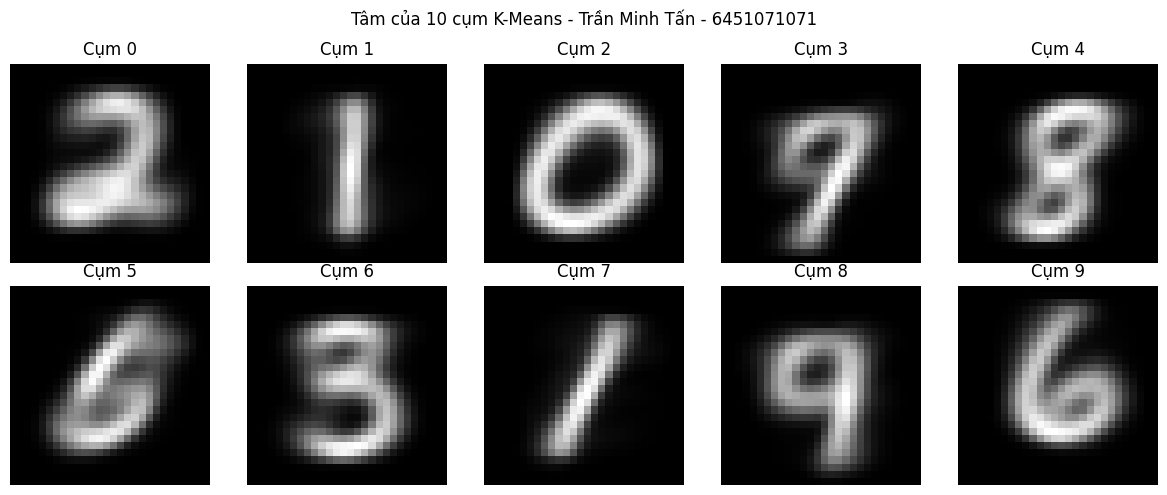

In [4]:
print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(kmeans.cluster_centers_[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Cụm {i}")
    ax.axis("off")
plt.suptitle("Tâm của 10 cụm K-Means - Trần Minh Tấn - 6451071071")
plt.tight_layout()
plt.show()

## 5. So sánh kết quả gom cụm với nhãn lớp có sẵn

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Bảng đối chiếu cụm với nhãn thật:
Nhãn thật     0     1     2     3     4     5     6     7     8     9
Cụm                                                                  
0             7     9  4157   173    29     5    53    40    44    17
1             2  3650   381   407   154   149   185   336   315   255
2          4308     0    44    22     7    54    53    20    29    41
3             5    10    68    36  1883   163     3  3774   165  2448
4            79     8   170   956    14  1009    16    15  3516    72
5          1087     6   210   431   211  1568  1693    10   261    23
6           232     6   276  3857     0  1807    34     5  1028    81
7             2  3042   330    49   208   233    39   256   273    85
8            45     6   190   171  3193   372    55  1805   178  2918
9           156     5   132    29   143    61  3787     4    42     9


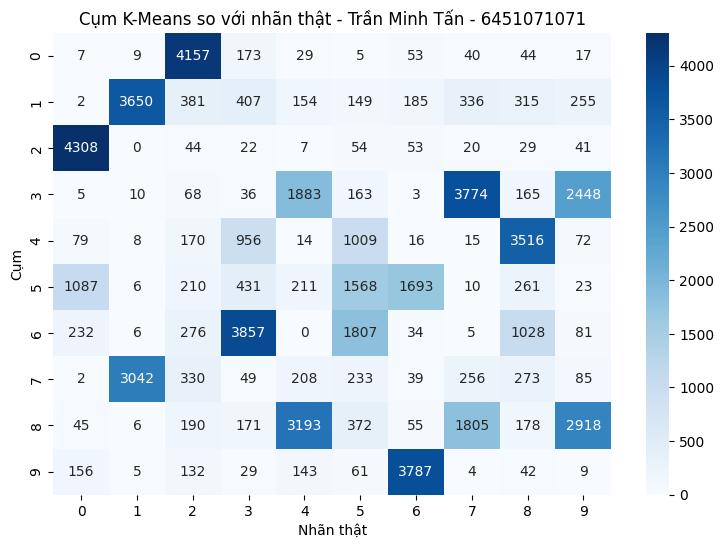

In [5]:
# Bảng đối chiếu: hàng = cụm, cột = nhãn thật (số lượng ảnh)
ct = pd.crosstab(clusters, y, rownames=["Cụm"], colnames=["Nhãn thật"])

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Bảng đối chiếu cụm với nhãn thật:")
print(ct)

plt.figure(figsize=(9, 6))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Cụm K-Means so với nhãn thật - Trần Minh Tấn - 6451071071")
plt.show()

In [6]:
from sklearn.metrics import (accuracy_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score)

# Mỗi cụm được gán nhãn là chữ số xuất hiện nhiều nhất trong cụm đó
cluster_to_label = {c: ct.loc[c].idxmax() for c in ct.index}
y_pred = np.array([cluster_to_label[c] for c in clusters])

print("Họ tên: Trần Minh Tấn - MSSV: 6451071071")
print("Nhãn gán cho từng cụm (theo đa số):")
for c, l in cluster_to_label.items():
    purity = ct.loc[c].max() / ct.loc[c].sum()
    print(f"  Cụm {c} -> chữ số {l} (độ thuần khiết {purity:.2%})")

print(f"\nĐộ chính xác sau khi gán nhãn cụm: {accuracy_score(y, y_pred):.4f}")
print(f"Adjusted Rand Index (ARI)        : {adjusted_rand_score(y, clusters):.4f}")
print(f"Normalized Mutual Info (NMI)     : {normalized_mutual_info_score(y, clusters):.4f}")
print(f"Homogeneity                      : {homogeneity_score(y, clusters):.4f}")

Họ tên: Trần Minh Tấn - MSSV: 6451071071
Nhãn gán cho từng cụm (theo đa số):
  Cụm 0 -> chữ số 2 (độ thuần khiết 91.69%)
  Cụm 1 -> chữ số 1 (độ thuần khiết 62.56%)
  Cụm 2 -> chữ số 0 (độ thuần khiết 94.10%)
  Cụm 3 -> chữ số 7 (độ thuần khiết 44.11%)
  Cụm 4 -> chữ số 8 (độ thuần khiết 60.05%)
  Cụm 5 -> chữ số 6 (độ thuần khiết 30.78%)
  Cụm 6 -> chữ số 3 (độ thuần khiết 52.65%)
  Cụm 7 -> chữ số 1 (độ thuần khiết 67.35%)
  Cụm 8 -> chữ số 4 (độ thuần khiết 35.74%)
  Cụm 9 -> chữ số 6 (độ thuần khiết 86.70%)

Độ chính xác sau khi gán nhãn cụm: 0.5829
Adjusted Rand Index (ARI)        : 0.3634
Normalized Mutual Info (NMI)     : 0.4978
Homogeneity                      : 0.4942


## 6. Nhận xét
- K-Means gom được các ảnh có hình dạng giống nhau vào cùng một cụm mà không cần nhãn; tâm cụm trông giống các chữ số.
- Một số chữ số có nét gần giống nhau (ví dụ 4 và 9, 3 và 5 và 8) dễ bị gom lẫn vào nhau, thể hiện ở những ô lớn nằm ngoài đường chéo của bảng đối chiếu.
- Độ chính xác chỉ ở mức trung bình vì K-Means dựa trên khoảng cách pixel, không hiểu hình dạng chữ số như mạng nơ-ron.